<a href="https://colab.research.google.com/github/Atin2001/GCI/blob/main/GCI2026W_%E7%AC%AC3%E5%9B%9E_Python%E3%81%AB%E3%82%88%E3%82%8B%E7%A7%91%E5%AD%A6%E8%A8%88%E7%AE%97%EF%BC%88NumPy%EF%BC%89_%E8%AC%9B%E7%BE%A9%E8%B3%87%E6%96%99_ipynb_%E3%81%AE%E3%82%B3%E3%83%94%E3%83%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NumPyで学ぶ はじめてのバイブコーディング

今回は、NumPyを題材にして、**生成AIに目的を伝え、コードを生成・実行し、結果を確認して修正する**という一連のプログラミング作業を体験します。

NumPyは、Pythonで数値計算を行うために広く使われているライブラリで、機械学習やデータ分析でも頻繁に利用されます。ただし、この講義ではNumPyの機能を細かく暗記することをゴールにはしません。

## 本日の講義の目標
### バイブコーディング

Geminiに実現したい処理を日本語で伝え、生成されたコードを実際に動かしながら確認・修正できるようになることを目指します。

- 自然言語（日本語）でやりたいことを伝えてコードを生成する
- 生成されたコードを実行して動作を確認する
- 仕組みが分からないコードについてGeminiに説明してもらう
- 期待した結果と実際の結果を比較・検証する
- 必要に応じて追加の指示や修正（デバッグ）を依頼する
- 自分の疑問や仮説をもとに、簡単なデータ分析を試す

### NumPy

宿題や、AIが生成したNumPyコードを読み解くために、次の基本を押さえます。

1. **NumPyとは何か**
2. **1次元配列の基本**
   - 配列全体に対するまとめての計算
   - 条件式を使った`True` / `False`配列の作成
   - 複数の条件の組み合わせ
   - 条件に当てはまる値だけの抽出
3. **条件抽出処理を関数にまとめる**
   - 条件式を分けて確認し、`return`で結果を返す

ユニバーサル関数、ブロードキャスト、インデクシングなどの用語にも触れますが、細かな記法まで暗記する必要はありません。必要になった段階で、AIやドキュメントを参照できれば十分です。
より詳しい内容や、本編で扱わないNumPyの機能は、付録のNotebookで確認できます。

授業内では、条件抽出の練習用データとしてNumPy配列を使用し、自由分析では15人分の架空の学習・成績データを扱います。


# 0. 実行環境の準備とNumPyの基礎

## 0-1. NumPyのインポート

まずはNumPyライブラリをインポート（読み込み）します。
Pythonでは慣習として、NumPyに`np`という別名をつけて利用します。


In [1]:
import numpy as np  # NumPyをnpという名前でインポート

print("NumPy version:", np.__version__)


NumPy version: 2.1.3


## 0-2. NumPyとは

NumPy（Numerical Python）は、Pythonで効率的な数値計算を行うためのライブラリです。

NumPyを使うと、複数の数値を**配列**としてまとめて扱い、配列全体に対して一度に計算できます。

```python
scores = np.array([60, 75, 90, 80])
```

このようなNumPyの配列オブジェクトを`ndarray`と呼びます。


### 0-2-1. NumPyの1次元配列

NumPyでは、`np.ndarray`を使って数値の並びを表現します。
Python標準のリストは、`np.array()`に渡すことでNumPy配列に変換できます。

ここでは例として、4人の生徒のテスト点数を1次元配列にしてみます。

```python
scores = np.array([60, 75, 90, 80])
```

配列の形状（次元や要素数）を確認するには、`shape`属性を使います。

```text
shape=(4,)
```

これは、「4個の要素を持つ1次元配列」であることを表しています。

NumPyの1次元配列は、数学のベクトルのように扱えます。
このあと、配列全体への一括計算や、値の抽出、平均値の計算などを行っていきます。


In [ ]:
import numpy as np

scores = np.array([60, 75, 90, 80])

print("scores:", scores)
print("shape :", scores.shape)


scores: [60 75 90 80]
shape : (4,)


Python標準のリストとNumPy配列は見た目が似ていますが、計算するときの動作が異なります。

たとえば、Python標準のリスト同士を足すと、

```python
[1, 2] + [3, 4]
```

2つのリストが結合され、`[1, 2, 3, 4]`になります。

一方、NumPy配列同士を足すと、対応する位置の要素同士が計算されます。
この違いは、数値計算でNumPyを使う理由を理解するための代表的な例です。


In [2]:
import numpy as np

list_a = [1, 2]
list_b = [3, 4]

array_a = np.array([1, 2])
array_b = np.array([3, 4])

print("Pythonのリスト:", list_a + list_b)
print("NumPy配列     :", array_a + array_b)


Pythonのリスト: [1, 2, 3, 4]
NumPy配列     : [4 6]


NumPy配列を使うと、`for`文で要素を1つずつ処理しなくても、配列全体に対する計算をまとめて記述できます。

このように、**複数の数値をひとまとまりの配列として扱い、まとめて計算できる**ことがNumPyの大きな特徴です。

なお、配列に入っている値のデータ型は`dtype`属性で確認できます。
`int64`などの細かな型名は本編では扱わず、別Notebookの**付録A**で補足します。


### 0-2-2. `np.ndarray`での基本的な計算

NumPy配列の便利な点の1つは、配列の中の値を1つずつ取り出して処理しなくても、配列全体に対してまとめて計算できることです。

たとえば、次のように書くと、

```python
scores + 5
scores * 2
```

`scores`に入っている4人分の点数それぞれに対して、5を足したり、2倍したりできます。

NumPyでは、このように配列の各要素に対して同じ計算をまとめて行う処理が多く用意されています。こうした処理の多くは、ユニバーサル関数（ufunc）という仕組みで実現されています。

また、

```python
scores + 5
```

のように、配列`scores`と1つの数値`5`を計算すると、`5`が配列の各要素に対して使われます。

このように、形状の異なる値同士でも、一定のルールに従って計算できるように形を合わせる仕組みを**ブロードキャスト**と呼びます。

さらに、配列の中の値をまとめて1つの結果にする処理もよく使います。

たとえば、

```python
np.mean(scores)
np.max(scores)
```

とすると、それぞれ平均値や最大値を求められます。

このように、複数の値をまとめて1つの結果にする関数を**集約関数**と呼びます。


In [ ]:
import numpy as np

scores = np.array([60, 75, 90, 80])

print("元の点数:", scores)
print("5点加点 :", scores + 5)
print("2倍     :", scores * 2)
print("平均  :", np.mean(scores))
print("最大値:", np.max(scores))
print("最小値:", np.min(scores))

元の点数: [60 75 90 80]
5点加点 : [65 80 95 85]
2倍     : [120 150 180 160]
平均  : 76.25
最大値: 90
最小値: 60


AIから知らないNumPy関数が提案された場合も、焦らず「この関数は何を入力とし、どのような結果を返すのか」をAIを使ったり、公式ドキュメントなどを確認していく習慣をつけていきましょう。NumPyの関数を暗記することは目標としなくて大丈夫です。


# 1. バイブコーディングとは

## 1-1. バイブコーディング（Vibe Coding）とは

「バイブコーディング（Vibe Coding）」は、やりたいことを自然言語で生成AIに伝え、AIにコードを書いてもらいながら開発を進めるスタイルを指す言葉です。

たとえば、

「このデータの平均を計算したい」
「80点以上の人だけ取り出したい」

といった目的を日本語で伝えると、AIがそれを実現するためのコードを提案してくれます。

必要に応じて、

- コードを実行する
- 結果を確認する
- エラーや意図と違う点をAIに伝える
- コードを修正してもらう

といったやり取りを繰り返しながら、処理を完成させていきます。

元々の「Vibe Coding」という言葉には、コードの細かな書き方をすべて自分で考えるよりも、AIとのやり取りを通して素早く形にしていくというニュアンスがあります。

アイデアを短時間で試したり、知らない書き方を使ってみたりするときには便利ですが、AIが生成したコードが必ず正しいとは限りません。

そのため、この講義では、AIにコードを書いてもらうだけでなく、実行結果を確認し、目的に合っているかを確かめることも重視します。


## 1-2. この講義で実践するバイブコーディング

この講義では、自然言語で目的をAIに伝えつつ、生成されたコードを実行し、結果を人間が確認・修正していく形でバイブコーディングを体験します。

大まかには、**AIがコードの作成を支援し、人間が目的の設定と結果の確認を担う**という役割分担で進めます。

たとえば、4人の点数データ

```text
60, 75, 90, 80
```

に対して、Geminiへ次のように依頼できます。

```text
4人の点数をNumPy配列にして、
全員に5点を加えた結果を表示するPythonコードを書いてください。
```

生成されたコードを実行したあと、必要であれば次のように追加の指示を出します。

```text
元の点数と、5点を加えた後の点数の両方が比較できるように表示してください。
```


それでは、この操作を1-3でやってみましょう。

## 1-3. Geminiを動かしてみる：最初のコード生成

まずはGeminiに短いコードを1つ生成してもらい、実際に手元で動かしてみましょう。

この段階では、プロンプトの細かな工夫やNumPyの詳細な仕様を意識する必要はありません。
**日本語で依頼するとコードが生成され、それを実行して結果を確認できる**という流れを体験することが目的です。

### 演習課題

4人の生徒の点数

```text
60, 75, 90, 80
```

の平均点を、NumPyを使って求めてみます。

Colab上でGeminiのチャットを開き、指示文を送ってみましょう。


### 操作ステップ1：Geminiのチャットパネルを開く

1. このNotebookをGoogle Colabで開きます。
2. Googleアカウントにログインしていることを確認します。
3. ノートブック画面に表示されるGeminiのアイコン（青いきらめきマーク）をクリックします。
4. サイドバーなどに表示されるチャット入力欄を確認します。

#### アイコンが表示されない場合の確認項目

- ブラウザのページを再読み込みする
- Googleアカウントへのログイン状態を確認する
- 利用中のアカウントの言語・地域設定を確認する
- 学校や企業などの組織アカウントで利用制限がないか確認する

ColabのAI機能は、利用環境やアカウント状態によって提供状況が異なる場合があります。
利用できない場合は、講師画面のデモを確認し、コードセルへ直接入力して学習を進めてください。また、模範例を載せたNotebookも用意しておりますのでそちらを利用してください。


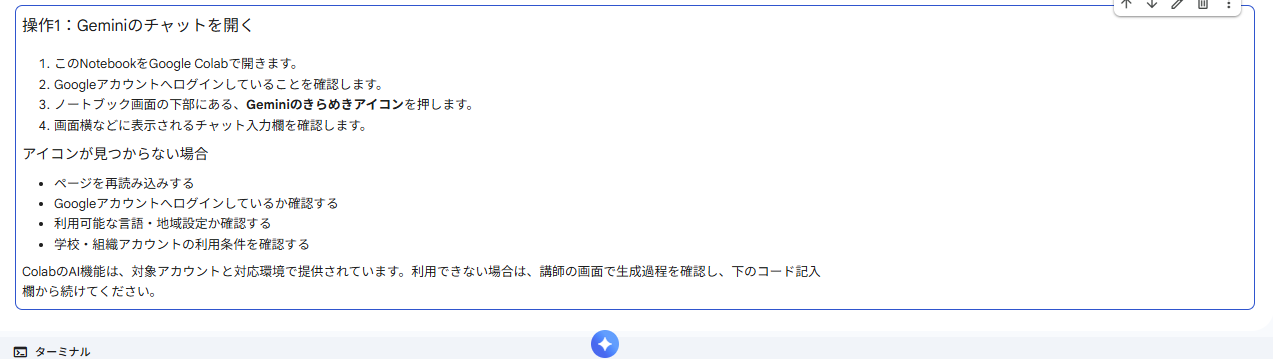

### 操作ステップ2：Geminiへ指示文（プロンプト）を送る
次のプロンプトをコピペしてGeminiに指示を出してみましょう。

```text
4人の点数 60, 75, 90, 80 の平均点を、
NumPyを使って求めるコードを書いてください。

Pythonの初学者にも分かるように、コードを短く説明してください。
```




In [3]:
import numpy as np

# 4人の点数をNumPy配列にする
scores = np.array([60, 75, 90, 80])

# 平均点を計算する
average_score = np.mean(scores)

# 結果を表示する
print("平均点:", average_score)

平均点: 76.25


Geminiがコードを生成したら、まず内容を確認してから実行します。

AIがノートブックの編集や実行を提案した場合は、画面に表示される確認操作（例：「承認して実行」「許可」など）を選びます。
表示名はColabの更新によって変わる場合があります。

コードだけが返ってきた場合は、次のセルに貼り付けて実行しても構いません。

In [ ]:
# Geminiが生成したコードを、このセルに貼り付けて試してください。

print("ここにGeminiのコードを貼り付けてから実行してください")


ここにGeminiのコードを貼り付けてから実行してください


### 操作ステップ3：コードを実行してみる

この時点では、生成されたコードをすべて理解できなくても構いません。

まずは、次の点を確認してください。

- Geminiにコードを生成してもらえた
- Colab上でコードを実行できた
- 平均点が1つ表示された

まずはここまでで十分です。

次は、答えがあらかじめ決まっている「平均を求める」課題ではなく、もう少し自由度の高いデータ分析を試します。



## 1-4. 実習：成績データを自由に分析してみる

先ほどは、やることが決まった簡単なコードをGeminiに生成してもらいました。

今度は、何を調べるかも含めてGeminiに提案してもらい、もう少し自由にデータを触ってみます。

ここでは、まだNumPyの詳しい使い方やプロンプトの書き方は説明していません。  
**正しい頼み方を考えすぎず、まず自由に試してみる**ことが目的です。

使うデータは、15人分の架空の学習・成績データです。

| 列名 | 意味 |
|---|---|
| `study_hours` | 1週間あたりの自主学習時間 |
| `absences` | 一定期間の欠席日数 |
| `math` | 数学の点数 |
| `science` | 理科の点数 |
| `japanese` | 国語の点数 |
| `english` | 英語の点数 |
| `social_studies` | 社会の点数 |

下のセルをそのまま実行すればデータを使えます。

このデータはすべて架空です。


In [4]:
import numpy as np

# 架空の15人分の学習・成績データ
# 列の順番:
# study_hours, absences, math, science, japanese, english, social_studies

column_names = [
    "study_hours",
    "absences",
    "math",
    "science",
    "japanese",
    "english",
    "social_studies",
]

student_data = np.array([
    [14.5,  4, 53, 56, 80, 80, 74],
    [ 7.7,  1, 77, 78, 78, 86, 76],
    [12.5,  1, 86, 89, 71, 61, 74],
    [11.4,  4, 54, 52, 67, 62, 62],
    [12.5,  8, 72, 64, 71, 62, 80],
    [11.1,  6, 74, 73, 55, 67, 66],
    [ 4.7,  4, 45, 60, 56, 57, 69],
    [ 7.2,  7, 49, 57, 69, 74, 82],
    [ 9.1,  7, 65, 80, 75, 67, 74],
    [13.3,  0, 64, 66, 51, 65, 64],
    [ 8.4, 10, 64, 66, 58, 64, 51],
    [ 2.0,  7, 44, 42, 42, 43, 43],
    [12.2,  4, 64, 66, 94, 88, 91],
    [ 8.3,  5, 71, 60, 63, 81, 86],
    [ 4.8,  3, 60, 53, 77, 67, 69],
])

print("列名:", column_names)
print("shape:", student_data.shape)
print(student_data)


列名: ['study_hours', 'absences', 'math', 'science', 'japanese', 'english', 'social_studies']
shape: (15, 7)
[[14.5  4.  53.  56.  80.  80.  74. ]
 [ 7.7  1.  77.  78.  78.  86.  76. ]
 [12.5  1.  86.  89.  71.  61.  74. ]
 [11.4  4.  54.  52.  67.  62.  62. ]
 [12.5  8.  72.  64.  71.  62.  80. ]
 [11.1  6.  74.  73.  55.  67.  66. ]
 [ 4.7  4.  45.  60.  56.  57.  69. ]
 [ 7.2  7.  49.  57.  69.  74.  82. ]
 [ 9.1  7.  65.  80.  75.  67.  74. ]
 [13.3  0.  64.  66.  51.  65.  64. ]
 [ 8.4 10.  64.  66.  58.  64.  51. ]
 [ 2.   7.  44.  42.  42.  43.  43. ]
 [12.2  4.  64.  66.  94.  88.  91. ]
 [ 8.3  5.  71.  60.  63.  81.  86. ]
 [ 4.8  3.  60.  53.  77.  67.  69. ]]


このデータについて、Geminiに**NumPyを使って自由に分析**してもらってください。

最初の依頼は、自分の言葉で書いて構いません。  
たとえば、

```text
このデータをNumPyを使って自由に分析してください。
気になる特徴や傾向があれば教えてください。
```

くらいでも構いません。

Geminiが出したコードをColabで実行し、どんな結果が出るか見てください。

この段階では、まだ習っていないNumPyの関数が出てきても問題ありません。  
最後に同じデータをもう一度分析するので、次の3点だけ残しておきます。


In [5]:
import numpy as np

# データの列インデックスを確認
# 0: study_hours, 1: absences, 2: math, 3: science, 4: japanese, 5: english, 6: social_studies

print("=== 1. 全体の平均値 ===")
means = np.mean(student_data, axis=0)
for name, mean_val in zip(column_names, means):
    print(f"{name:<15}: {mean_val:.2f}")

print("\n=== 2. 勉強時間による違い (平均 9.69時間以上 vs 未満) ===")
study_hours = student_data[:, 0]
mean_study = np.mean(study_hours)

# 条件に合うデータのインデックス（マスク）を作成
high_study_mask = study_hours >= mean_study
low_study_mask = study_hours < mean_study

high_study_scores = np.mean(student_data[high_study_mask, 2:], axis=0)
low_study_scores = np.mean(student_data[low_study_mask, 2:], axis=0)

print(f"勉強時間 {mean_study:.1f}時間以上のグループ（{np.sum(high_study_mask)}人）の平均点:")
for name, score in zip(column_names[2:], high_study_scores):
    print(f"  {name:<15}: {score:.1f}")

print(f"勉強時間 {mean_study:.1f}時間未満のグループ（{np.sum(low_study_mask)}人）の平均点:")
for name, score in zip(column_names[2:], low_study_scores):
    print(f"  {name:<15}: {score:.1f}")

print("\n=== 3. 欠席日数による違い (5日以上 vs 5日未満) ===")
absences = student_data[:, 1]

high_abs_mask = absences >= 5
low_abs_mask = absences < 5

high_abs_scores = np.mean(student_data[high_abs_mask, 2:], axis=0)
low_abs_scores = np.mean(student_data[low_abs_mask, 2:], axis=0)

print(f"欠席5日以上のグループ（{np.sum(high_abs_mask)}人）の平均点:")
for name, score in zip(column_names[2:], high_abs_scores):
    print(f"  {name:<15}: {score:.1f}")

print(f"欠席5日未満のグループ（{np.sum(low_abs_mask)}人）の平均点:")
for name, score in zip(column_names[2:], low_abs_scores):
    print(f"  {name:<15}: {score:.1f}")

=== 1. 全体の平均値 ===
study_hours    : 9.31
absences       : 4.73
math           : 62.80
science        : 64.13
japanese       : 67.13
english        : 68.27
social_studies : 70.73

=== 2. 勉強時間による違い (平均 9.69時間以上 vs 未満) ===
勉強時間 9.3時間以上のグループ（7人）の平均点:
  math           : 66.7
  science        : 66.6
  japanese       : 69.9
  english        : 69.3
  social_studies : 73.0
勉強時間 9.3時間未満のグループ（8人）の平均点:
  math           : 59.4
  science        : 62.0
  japanese       : 64.8
  english        : 67.4
  social_studies : 68.8

=== 3. 欠席日数による違い (5日以上 vs 5日未満) ===
欠席5日以上のグループ（7人）の平均点:
  math           : 62.7
  science        : 63.1
  japanese       : 61.9
  english        : 65.4
  social_studies : 68.9
欠席5日未満のグループ（8人）の平均点:
  math           : 62.9
  science        : 65.0
  japanese       : 71.8
  english        : 70.8
  social_studies : 72.4


In [ ]:
# 最初にGeminiへ送った文：
# ここに記入してください。

In [ ]:
# Geminiが見つけた特徴や傾向：
# ここに記入してください。

In [ ]:
# 分からなかったコードや、正しいか判断しにくかったところ：
# ここに記入してください。

## 1-5. AIと人間の役割分担

生成AIは、コード生成・説明・デバッグ・修正を手伝えます。

一方で、**何をしたいのか**と**結果が目的に合っているか**は人間が確認します。

| AIに頼めること | 人間が確認すること |
|---|---|
| コードを書く | 目的どおりの処理か |
| 分からないコードを説明する | 説明と実際の動作が合っているか |
| エラーや間違いの修正案を出す | 修正後に期待した結果になったか |

特に注意したいのは、

> **コードはエラーなく動いていても、計算内容が間違っていることがある**

という点です。

後半では、実際にそのようなコードをGeminiと一緒に修正します。


## 1-6. この講義で使う進め方の一例：PREDICT–ASK–RUN–CHECK–EXPLAIN

AIを使ったコーディングには、決まった1つの進め方があるわけではありません。
この講義では、生成されたコードをそのまま受け入れるのではなく、考えながら確認するための一つの進め方として、次の流れを使います。

1. **PREDICT：見通しを立てる**  
   どんな処理を、どの順番で行えばよいか考える

2. **ASK：AIに依頼する**  
   やりたいことを言葉で伝える

3. **RUN：実行する**  
   生成されたコードを動かす

4. **CHECK：結果を確かめる**  
   値、個数、`shape`などを確認する

5. **EXPLAIN：分からない処理を説明してもらう**  
   必要に応じてAIに質問し、自分でも大まかな処理を確認する

実際のAIコーディングでは、必ずこの順番で進める必要はありません。
途中でAIへの質問に戻ったり、RUNとCHECKを何度も繰り返したり、一部の工程を省略したりすることもあります。

この流れで特に意識したいのは、AIにコードを書いてもらうこと自体ではなく、「何をしたいのか」と「出てきた結果が目的に合っているか」を自分でも確認することです。

PREDICTも、計算結果を暗算することではありません。

たとえば、

```text
全員に10点を加えたあと、平均点を出したい
```

なら、

```text
点数を用意する
→ 全員に10点を加える
→ 平均を求める
→ 結果を確認する
```

という**処理の流れ**を先に考えます。


## 1-7. AIに依頼するときの5つの確認項目

AIへの依頼がうまく伝わらないときは、次の5つを確認すると整理しやすくなります。

| 項目 | 確認する内容 |
|---|---|
| 目的 | 何をしたいのか |
| 入力 | 変数名、データの意味、`shape`など |
| 出力 | 何を表示・計算したいのか |
| 制約 | NumPyを使う、短いコードにする、など |
| 検証 | 個数や`shape`も表示する、など |

毎回すべてをプロンプトに書く必要はありません。
まず短く依頼して、AIの回答が曖昧だったり意図と違ったりしたときに、足りない情報を追加していけば構いません。

この5項目は必ず守るテンプレートではなく、**依頼内容を見直すときの観点**として使ってください。


# 2. 1次元配列にまとめて計算する

ここからは、NumPyを用いて「ある条件に当てはまる値だけを配列から取り出す」処理を作っていきます。

たとえば、

- 3の倍数だけを見つける
- 奇数だけを見つける
- 「3の倍数かつ奇数」のように複数の条件に合う値だけを取り出す

といった処理です。

そのためには、まず配列に入っているすべての値に対して、同じ計算をまとめて行う方法を知る必要があります。

まず、整数を要素に持つ1次元配列を用意し、各要素を3や2で割った余りをまとめて計算してみます。

```python
a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])
```

NumPyでは、配列のすべての要素に対してまとめて計算できます。

たとえば、

```python
a % 3
```

とすると、`a`の各要素を3で割った余りが返ります。

同じように、

```python
a % 2
```

とすると、各要素を2で割った余りが返ります。

このように、NumPyでは**配列の各要素に対して同じ計算をまとめて行う**ことができます。

`a % 3`でも、先ほどの`scores + 5`と同じように、
1つの数値`3`が配列`a`の各要素に対して使われています。

ここではブロードキャストの仕組みそのものよりも、

> `a % 3`は「`a`のすべての要素を3で割った余り」

と読めることを押さえてください。

次は、この計算結果を使って、**「3の倍数かどうか」「奇数かどうか」を`True` / `False`で表してみます。**


In [ ]:
import numpy as np

a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])

print("a     :", a)
print("a % 3 :", a % 3)
print("a % 2 :", a % 2)


a     : [ 1  3  6  9 10 12 15 21 30]
a % 3 : [1 0 0 0 1 0 0 0 0]
a % 2 : [1 1 0 1 0 0 1 1 0]


### CHECK

`a % 3`と`a % 2`の結果は、元の配列と同じ要素数です。

NumPyでは、このように`for`文を書かなくても、配列全体に同じ計算を適用できます。

ここでのポイントは、

- `% 3`：3で割った余り
- `% 2`：2で割った余り
- 配列に対して演算すると、各要素に対して同じ演算が行われる

の3点です。


# 3. 条件から`True` / `False`の配列を作る

次に、計算結果を条件式にします。

```python
a % 3 == 0
```

は、

> 「3で割った余りが0か」

を各要素について確認しています。

結果は数値ではなく、`True` / `False`の配列になります。

同じように、

```python
a % 2 == 1
```

とすると、

> 「2で割った余りが1か」

つまり、奇数かどうかを各要素について確認できます。


In [ ]:
import numpy as np

a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])

condition_1 = (a % 3 == 0)
condition_2 = (a % 2 == 1)

print("3の倍数か        :", condition_1)
print("2で割って1余るか:", condition_2)


3の倍数か        : [False  True  True  True False  True  True  True  True]
2で割って1余るか: [ True  True False  True False False  True  True False]


### CHECK

条件式の結果は、

```text
[ True  True False ...]
```

のような**bool配列**になります。

この段階では、まだ値を取り出していません。

まず、

> **条件を書く → 各要素について`True` / `False`ができる**

という流れを確認してください。


# 4. 複数の条件を組み合わせて値を取り出す

2つの条件を両方満たす要素を探したいときは、NumPyでは`&`を使います。

```python
condition = condition_1 & condition_2
```

これは、

> condition_1 **かつ** condition_2

という意味です。

そして、

```python
a[condition]
```

とすると、`condition`が`True`になっている位置の値だけを取り出せます。

これを**ブールインデックス参照**と呼びます。


In [ ]:
import numpy as np

a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])

condition_1 = (a % 3 == 0)
condition_2 = (a % 2 == 1)
condition = condition_1 & condition_2

print("条件1:", condition_1)
print("条件2:", condition_2)
print("両方 :", condition)
print("抽出 :", a[condition])


条件1: [False  True  True  True False  True  True  True  True]
条件2: [ True  True False  True False False  True  True False]
両方 : [False  True False  True False False  True  True False]
抽出 : [ 3  9 15 21]


ここまでの流れを1つにつなげると、

```python
a[(a % 3 == 0) & (a % 2 == 1)]
```

のように書けます。

一見すると長く見えますが、内側から読むと、

```text
a % 3 == 0
→ 3の倍数か

a % 2 == 1
→ 2で割って1余るか

&
→ 両方を満たすか

a[ ... ]
→ Trueの場所だけ取り出す
```

という4段階です。

NumPy配列の条件を組み合わせるときは、`and`ではなく`&`を使います。
また、それぞれの条件を`()`で囲んでおくと読みやすく、意図しない計算を防ぎやすくなります。


# 5. 条件抽出を関数にまとめる

ここまでの処理を、最後に関数へまとめます。
整数値を持つNumPyの1次元配列`a`を受け取り、

> **3の倍数かつ、2で割って1余る数**

だけを返す`practice_filter`関数を作ります。

処理の流れは、

```text
入力 a
→ 3の倍数か判定
→ 2で割って1余るか判定
→ 2つの条件を & で組み合わせる
→ Trueの位置だけ取り出す
→ return
```

です。


In [ ]:
import numpy as np

def practice_filter(a):
    condition_1 = (a % 3 == 0)
    condition_2 = (a % 2 == 1)
    return a[condition_1 & condition_2]

a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])

print(practice_filter(a))


[ 3  9 15 21]


この関数では、

```python
return a[condition_1 & condition_2]
```

によって、条件を満たすNumPy配列を返しています。

慣れてきたら、条件式を1行にまとめることもできます。
ただし、最初は`condition_1`、`condition_2`に分けた方が、
AIが生成したコードを確認しやすくなります。

宿題でも、条件に使う数字が変わっても**考え方は同じ**です。


# 6. Geminiに似た条件抽出課題を書いてもらう

ここからは、条件抽出のコードを**すべて自分で書くのではなく、Geminiに依頼して作ってもらいます。**

### 課題

整数値を持つNumPyの1次元配列`a`から、

> **7の倍数かつ、2で割って1余る数**

だけを返す関数を作ってください。

### PREDICT

Geminiへ依頼する前に、処理の流れを考えてみます。

```text
入力 a
→ __________________________________
→ __________________________________
→ 2つの条件を組み合わせる
→ 条件に合う値だけ取り出す
→ return
```

### ASK

自分の言葉でGeminiへ依頼してください。

必要であれば、

- 入力はNumPyの1次元配列
- 返り値もNumPy配列
- `for`文は使わない
- 条件式を2つに分けて説明する
- 最後にテスト用の配列で動作確認する

と伝えます。

### RUN / CHECK / EXPLAIN

実行したあと、

- 7の倍数だけになっているか
- さらに奇数だけになっているか
- `&`が何をしているか説明できるか
- `a[condition]`が何をしているか説明できるか

を確認してください。


In [ ]:
# メモ用にGeminiに渡したプロンプトをここに書いてみましょう

In [ ]:
import numpy as np

a = np.array([1, 7, 14, 21, 28, 35, 42, 49, 50])

# Geminiが生成した関数を、この下に貼り付けて試してください。


print("入力:", a)


入力: [ 1  7 14 21 28 35 42 49 50]


# 7. AIが書いた未知コードを分解して理解する

Geminiが、たとえば関数の中に次のような1行を書いたとします。

```python
return a[(a % 7 == 0) & (a % 2 == 1)]
```

意味が分からない場合は、そのまま受け入れず、処理を分けて確認します。

### ASK：1行を分解して説明してもらう

次のように聞いてみます。

```text
次の1行を、内側から順番に5段階に分けて説明してください。

return a[(a % 7 == 0) & (a % 2 == 1)]

特に、
1. a % 7
2. == 0
3. a % 2 == 1
4. &
5. a[ ... ]
がそれぞれ何をしているか知りたいです。

最後に、この関数が何をreturnしているかも説明してください。
```

### RUN：小さく分けて実行する

AIの説明を読むだけでなく、分からない部分を1つずつ実行して確かめます。


In [ ]:
import numpy as np

a = np.array([1, 7, 14, 21, 28, 35, 42, 49, 50])

step1 = a % 7
step2 = (a % 7 == 0)
step3 = (a % 2 == 1)
step4 = step2 & step3
step5 = a[step4]

print("1. a % 7              :", step1)
print("2. a % 7 == 0         :", step2)
print("3. a % 2 == 1         :", step3)
print("4. 条件1 & 条件2      :", step4)
print("5. a[条件]             :", step5)


1. a % 7              : [1 0 0 0 0 0 0 0 1]
2. a % 7 == 0         : [False  True  True  True  True  True  True  True False]
3. a % 2 == 1         : [ True  True False  True False  True False  True False]
4. 条件1 & 条件2      : [False  True False  True False  True False  True False]
5. a[条件]             : [ 7 21 35 49]


### CHECK

Geminiの説明と、実際に分けて実行した結果を比べます。

- `% 7`で各要素の余りが計算されたか
- `== 0`で`True` / `False`になったか
- `&`で両方の条件を満たす位置だけ`True`になったか
- `a[条件]`で対応する値だけ取り出されたか

ここで重要なのは、長い1行を暗記することではなく、**知らないコードが出ても、AIに分解して説明してもらい、自分でも小さく実行して確認できること**です。


# 8. AIを用いたデバッグ

次は、**エラーは出ないものの、目的とは異なる結果を返すコード**を確認します。

### 目的

「3の倍数**かつ**2で割って1余る数」を取り出したいとします。

しかし、次のコードでは条件を`|`でつないでいます。
コード自体は動きます。

まず実行して、期待した値より多くの値が取り出されることを確認してください。


In [ ]:
import numpy as np

a = np.array([1, 3, 6, 9, 10, 12, 15, 21, 30])

condition_1 = (a % 3 == 0)
condition_2 = (a % 2 == 1)

result = a[condition_1 | condition_2]  # あえて間違えています

print("結果:", result)


結果: [ 1  3  6  9 12 15 21 30]


Geminiには、**目的・実際のコード・実際の結果**を一緒に伝えます。

```text
NumPyの1次元配列aから、
「3の倍数かつ2で割って1余る数」だけを取り出したいです。

次のコードはエラーなく動きますが、条件に合わない値まで含まれます。

condition_1 = (a % 3 == 0)
condition_2 = (a % 2 == 1)
result = a[condition_1 | condition_2]

なぜ目的と違う結果になるのか説明し、
最小限の修正だけ示してください。
```

修正後は、

- 「かつ」という条件になったか
- 条件を満たさない値が混ざっていないか
- `|`と`&`の違いを説明できるか

を確認します。

ここでは、

> **コードが動いたことではなく、条件と出力が目的に合っていることを確認する**

のがポイントです。


# 9. 自由課題：最初と同じデータをもう一度分析する

ここまで、Geminiと対話しながらコードを生成・実行・確認してきました。最後に、講義の最初に使った15人分の架空の学習・成績データをもう一度分析します。

最初は「まずGeminiに自由に頼んでみる」ところから始めました。

今度は、

- 自分で問いを決める
- コードの見通しを立てる
- AIに依頼する
- 知らないコードはAIに説明してもらう
- 結果が目的と合っているか確認する
- 必要なら修正を頼む

という流れを意識して分析します。


まず、改めてデータを定義します。

In [ ]:
import numpy as np

# 架空の15人分の学習・成績データ
# 列の順番:
# study_hours, absences, math, science, japanese, english, social_studies

column_names = [
    "study_hours",
    "absences",
    "math",
    "science",
    "japanese",
    "english",
    "social_studies",
]

student_data = np.array([
    [14.5,  4, 53, 56, 80, 80, 74],
    [ 7.7,  1, 77, 78, 78, 86, 76],
    [12.5,  1, 86, 89, 71, 61, 74],
    [11.4,  4, 54, 52, 67, 62, 62],
    [12.5,  8, 72, 64, 71, 62, 80],
    [11.1,  6, 74, 73, 55, 67, 66],
    [ 4.7,  4, 45, 60, 56, 57, 69],
    [ 7.2,  7, 49, 57, 69, 74, 82],
    [ 9.1,  7, 65, 80, 75, 67, 74],
    [13.3,  0, 64, 66, 51, 65, 64],
    [ 8.4, 10, 64, 66, 58, 64, 51],
    [ 2.0,  7, 44, 42, 42, 43, 43],
    [12.2,  4, 64, 66, 94, 88, 91],
    [ 8.3,  5, 71, 60, 63, 81, 86],
    [ 4.8,  3, 60, 53, 77, 67, 69],
])

print("列名:", column_names)
print("shape:", student_data.shape)
print(student_data)


列名: ['study_hours', 'absences', 'math', 'science', 'japanese', 'english', 'social_studies']
shape: (15, 7)
[[14.5  4.  53.  56.  80.  80.  74. ]
 [ 7.7  1.  77.  78.  78.  86.  76. ]
 [12.5  1.  86.  89.  71.  61.  74. ]
 [11.4  4.  54.  52.  67.  62.  62. ]
 [12.5  8.  72.  64.  71.  62.  80. ]
 [11.1  6.  74.  73.  55.  67.  66. ]
 [ 4.7  4.  45.  60.  56.  57.  69. ]
 [ 7.2  7.  49.  57.  69.  74.  82. ]
 [ 9.1  7.  65.  80.  75.  67.  74. ]
 [13.3  0.  64.  66.  51.  65.  64. ]
 [ 8.4 10.  64.  66.  58.  64.  51. ]
 [ 2.   7.  44.  42.  42.  43.  43. ]
 [12.2  4.  64.  66.  94.  88.  91. ]
 [ 8.3  5.  71.  60.  63.  81.  86. ]
 [ 4.8  3.  60.  53.  77.  67.  69. ]]


## 9-1. 今度は、分析したいことを自分で決める

列の意味をもう一度確認します。

| 列名 | 意味 |
|---|---|
| `study_hours` | 1週間あたりの自主学習時間 |
| `absences` | 一定期間の欠席日数 |
| `math` | 数学の点数 |
| `science` | 理科の点数 |
| `japanese` | 国語の点数 |
| `english` | 英語の点数 |
| `social_studies` | 社会の点数 |

今度は、いきなり「全部分析して」と頼むのではなく、**自分なりの仮説や疑問を1つ決めて**からGeminiを使います。

たとえば、

- 勉強時間が長い人ほど、点数も高そうか
- 欠席が多い人は、点数が低そうか
- 似た動きをしている科目はありそうか
- 数学が高い人は理科も高そうか
- ほかに自分が気になったこと

などから考えても構いません。

ここに書いてある例とは別の問いでも構いません。



In [ ]:
# 自分の仮説・調べたいこと

# ここに記入してください。

## 9-2. コードの見通しを立てる

正確なPythonコードでなくて構いません。  
どの列を使って、どんな順番で確かめればよさそうかを書きます。

In [ ]:
# コードの見通し
# ここに記入してください。

## 9-3. Geminiへ依頼する

プロンプトは自由に書いて構いません。

必要であれば、ここまでに扱った

**目的・入力・出力・制約・検証**

を思い出してください。テンプレートをそのまま使う必要はありません。

In [ ]:
# Geminiへ送った文

# ここに記入してください。

## 9-4. 実行して確認する

生成されたコードを実行して、次を確認します。

- 自分が調べたかったことに答えているか
- 生成されたコードの中で、分からないNumPyの処理をGeminiに質問したか
- 値や`shape`など、結果を確認したか
- 自分の問いに答えていなければGeminiへ修正を頼んだか

In [ ]:
# 分かったこと
# ここに記入してください。

# 確認・修正したこと
# ここに記入してください。

## 9-5. 最初と比べる

講義の最初に同じデータを分析したときと比べます。

In [ ]:
# 最初と比べて変わったことを1つ書いてください。
# ここに記入してください。

# 講義のまとめ

今回の講義では、**NumPyを題材にして、Geminiと一緒にコードを作り、実行・確認・修正する流れ**を体験しました。

この講義では、AIを使ってコードを書くときの一つの進め方として、

```text
PREDICT
何をどの順番で行うか考える
↓
ASK
AIに依頼する
↓
RUN
生成されたコードを動かす
↓
CHECK
条件や値を確認する
↓
EXPLAIN
分からないコードをAIに説明してもらう
↓
必要なら修正して、もう一度試す
```

という流れを使いました。

これは固定された手順ではありません。実際には、必要に応じて前の段階に戻ったり、実行と確認を何度も繰り返したりします。

NumPyでは、1次元配列の条件抽出に必要な、

```python
a % 3
a % 3 == 0
a % 2 == 1

condition_1 & condition_2

a[condition]
```

という処理を確認しました。

条件抽出は、

```text
配列全体に計算する
→ 条件をTrue / Falseにする
→ 条件を組み合わせる
→ Trueの位置だけ取り出す
→ returnで結果を返す
```

と分けて考えることができます。

また、`a % 3`のような「配列と1つの数値」の計算を通して、NumPyの基本的な特徴である**ブロードキャスト**も確認しました。

さらに、Geminiが生成した長い1行のコードも、

```text
% → 比較 → 条件の結合 → インデクシング → return
```

のように小さく分けて説明してもらい、実際に1段階ずつ実行して確認しました。

すべてのNumPy関数を覚える必要はありません。

今回の目標は、**分からないコードが出てきても、AIに質問しながら実行・確認・修正を進められること**です。

NumPyについてもう少し学びたい場合は、2次元配列・`shape`・`axis`などを扱った付録のNotebookも確認してください。
